# Deep Learning Text Classifier: SMS Spam Filter (PyTorch)
**Goal:** classify a text message as **spam** or **not spam (ham)** and report a confidence.

**Pipeline**
1. Build / load a labelled text dataset
2. Split into train / validation / test **before** any text processing
3. Turn text into numbers with **TF-IDF** (fitted on the training set only)
4. Multi-layer PyTorch network with **Dropout**, **Batch Normalization** and **early stopping**
5. Plot loss and accuracy curves
6. Evaluate on the unseen test set (precision, recall, F1, ROC-AUC, confusion matrix)
7. Predict on brand-new messages with confidence scores

**Data note:** this notebook was built in a sandbox with no internet, so the messages are *synthetic*: generated from templates with shared vocabulary between spam and normal messages, typos, random noise words and ~3% wrong labels, so the task is not trivial. To use a real dataset (for example the UCI SMS Spam Collection), replace only the loading cell with a table that has `text` and `label` columns.

In [1]:
import re, random, copy, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)
warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
print('PyTorch', torch.__version__)

PyTorch 2.15.0+cu132


## 1. Load data
**Swap this cell for real data.** The rest of the notebook needs a DataFrame `df` with `text` and `label` (1 = spam, 0 = ham).

In [2]:
def make_synthetic_sms(n=4000, seed=SEED):
    rng = random.Random(seed)
    names = ['Sam', 'Priya', 'Ravi', 'Anna', 'Mohan', 'Lisa', 'Karan', 'Meera']
    places = ['office', 'station', 'cafe', 'mall', 'gym', 'airport', 'college', 'home']
    times = ['5pm', 'tomorrow', 'tonight', 'at 8', 'on Monday', 'after lunch', 'this weekend']
    prizes = ['a free iPhone', 'cash prize of $1000', 'a free holiday', 'a gift voucher', '500 reward points']
    banks = ['HDFC', 'SBI', 'ICICI', 'PayPal', 'Amazon', 'Netflix']
    ham_t = [
        'hey {n} are you coming to the {p} {t}', 'call me when you reach the {p}', 'can you send me the notes from class {t}',
        'lunch at the {p} {t} ?', 'i will be late, stuck at the {p}', 'thanks for the help yesterday, free {t}?',
        'happy birthday {n}! hope you win big this year', 'did you get my message about the {p}',
        'meeting moved to {t}, please confirm', 'dont forget to pick up milk from the {p}',
        'the free trial of the app ends {t}, want to cancel it?', 'mom says call her {t}',
        'your parcel from {n} arrived at the {p}', 'text me the address of the {p}', 'won the match {t}, come celebrate',
        'reminder: dentist appointment {t}', 'i am free {t}, lets catch up', 'please reply when you see this'
    ]
    spam_t = [
        'WINNER! you have won {pr}. call now to claim', 'URGENT: your {b} account is suspended, verify at http://{b}-secure.com',
        'free entry to win {pr}, text WIN to 80082', 'congratulations {n}! claim {pr} before midnight, reply YES',
        'your {b} card has been blocked, click the link to restore access', 'limited offer: get {pr} now, call 0800 555 123',
        'you are selected for {pr}. msg STOP to opt out', 'final notice: claim your {pr} today',
        'cheap loans approved instantly, no documents, call now', 'hot singles near you, reply now',
        'earn money from home, join today, guaranteed income', 'your {b} reward is waiting, tap to redeem {pr}',
        'ur mobile number won {pr}, reply to claim', 'last chance! {pr} expires {t}, click here'
    ]
    noise = ['ok', 'yes', 'now', 'today', 'pls', 'dear', 'hello', 'info', 'the', 'please', 'new', 'alert']
    rows = []
    for _ in range(n):
        spam = rng.random() < 0.27
        t = rng.choice(spam_t if spam else ham_t)
        msg = t.format(n=rng.choice(names), p=rng.choice(places), t=rng.choice(times),
                       pr=rng.choice(prizes), b=rng.choice(banks))
        if rng.random() < 0.55:                       # add shared noise words to both classes
            msg = ' '.join(rng.sample(noise, rng.randint(1, 3))) + ' ' + msg if rng.random() < 0.5 else msg + ' ' + ' '.join(rng.sample(noise, rng.randint(1, 3)))
        if rng.random() < 0.15:                       # typos
            w = msg.split(); i = rng.randrange(len(w)); w[i] = w[i][::-1] if len(w[i]) > 3 else w[i]; msg = ' '.join(w)
        if spam and rng.random() < 0.20:              # make some spam sound casual
            msg = msg.lower().replace('urgent', 'hey').replace('winner', 'hi')
        label = int(spam)
        if rng.random() < 0.03: label = 1 - label     # label noise
        rows.append((msg, label))
    return pd.DataFrame(rows, columns=['text', 'label'])

df = make_synthetic_sms()
n_before = len(df)
df = df.drop_duplicates(subset='text').reset_index(drop=True)   # identical messages must not appear in both train and test
print('Removed', n_before - len(df), 'duplicate messages.', end=' ')
print(df.shape, '| spam share:', round(df.label.mean(), 3))
df.sample(6, random_state=1)

Removed 1346 duplicate messages. (2654, 2) | spam share: 0.314


,text,label
2449,"the free trial of the app ends tomorrow, want ...",0
1748,reminder: dentist appointment 5pm info,0
2621,call me when you reach the airport alert now new,0
2423,hey Karan are you coming to the station after ...,0
1400,alert WINNER! you have won a free iPhone. call...,1
760,"new cheap loans approved instantly, no documen...",1


## 2. Split first (train 70% / validation 15% / test 15%)
The test set is locked away until the very end. The validation set is used for early stopping.

In [3]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
print('train / val / test:', len(train_df), len(val_df), len(test_df))
print('spam share:', [round(d.label.mean(), 3) for d in (train_df, val_df, test_df)])
print('duplicate messages shared between train and test:', len(set(train_df.text) & set(test_df.text)))

train / val / test: 1857 398 399
spam share: [np.float64(0.314), np.float64(0.314), np.float64(0.313)]
duplicate messages shared between train and test: 0


## 3. Tokenize and vectorize with TF-IDF
TF-IDF turns each message into a vector: words that are frequent in a message but rare overall get a higher weight. It uses single words and word pairs (1-2 grams). The vectorizer **learns its vocabulary from the training set only**, so no information leaks from validation or test.

In [4]:
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=3000, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df.text)          # fit on train only
X_val, X_test = tfidf.transform(val_df.text), tfidf.transform(test_df.text)
y_train, y_val, y_test = (d.label.values.astype('float32') for d in (train_df, val_df, test_df))
print('Vocabulary size:', len(tfidf.vocabulary_), '| matrix shape (train):', X_train.shape)
print('Top words by weight example:', list(tfidf.vocabulary_)[:12])

to_t = lambda X: torch.tensor(X.toarray(), dtype=torch.float32)
Xt_train, Xt_val, Xt_test = to_t(X_train), to_t(X_val), to_t(X_test)
yt_train, yt_val, yt_test = (torch.tensor(y) for y in (y_train, y_val, y_test))
train_loader = DataLoader(TensorDataset(Xt_train, yt_train), batch_size=64, shuffle=True, drop_last=True)   # BatchNorm needs more than 1 row per batch

Vocabulary size: 1346 | matrix shape (train): (1857, 1346)
Top words by weight example: ['info', 'yes', 'today', 'will', 'be', 'late', 'stuck', 'at', 'the', 'gym', 'info yes', 'yes today']


## 4. The neural network
Input (3000 TF-IDF features) → **Linear 256 → BatchNorm → ReLU → Dropout 0.5** → **Linear 64 → BatchNorm → ReLU → Dropout 0.3** → Linear 1 (one score for "spam").

- **Batch Normalization** keeps layer inputs on a stable scale, which makes training steadier.
- **Dropout** randomly switches off neurons while training, so the network cannot rely on a few words and overfits less.
- **Early stopping** (below) stops training when validation loss stops improving.

In [5]:
class SpamNet(nn.Module):
    def __init__(self, n_in, h1=256, h2=64, p1=0.5, p2=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, h1), nn.BatchNorm1d(h1), nn.ReLU(), nn.Dropout(p1),
            nn.Linear(h1, h2), nn.BatchNorm1d(h2), nn.ReLU(), nn.Dropout(p2),
            nn.Linear(h2, 1))
    def forward(self, x):
        return self.net(x).squeeze(1)          # raw score (logit)

model = SpamNet(Xt_train.shape[1])
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

SpamNet(
  (net): Sequential(
    (0): Linear(in_features=1346, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 361985


## 5. Train with early stopping
Each epoch we train on the training set, then measure loss and accuracy on the validation set. If validation loss does not improve for `PATIENCE` epochs, training stops and the **best** weights are restored.

In [6]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4, weight_decay=1e-4)
MAX_EPOCHS, PATIENCE = 80, 8

def evaluate(X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = ((torch.sigmoid(logits) >= 0.5).float() == y).float().mean().item()
    return loss, acc

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val, best_state, best_epoch, wait = float('inf'), None, 0, 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
    tr_loss, tr_acc = evaluate(Xt_train, yt_train)       # eval mode: dropout off, so curves are comparable
    va_loss, va_acc = evaluate(Xt_val, yt_val)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    if va_loss < best_val - 1e-4:
        best_val, best_state, best_epoch, wait = va_loss, copy.deepcopy(model.state_dict()), epoch, 0
    else:
        wait += 1
    if epoch % 5 == 0 or wait == 0:
        print(f'epoch {epoch:2d}  train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}' + ('  *best' if wait == 0 else ''))
    if wait >= PATIENCE:
        print(f'Early stopping at epoch {epoch}. Best epoch was {best_epoch} (val loss {best_val:.4f}).')
        break
else:
    print('Reached max epochs. Best epoch was', best_epoch)

model.load_state_dict(best_state)       # restore best weights

epoch  1  train loss 0.7124 acc 0.314 | val loss 0.7135 acc 0.314  *best
epoch  2  train loss 0.5235 acc 0.963 | val loss 0.5336 acc 0.947  *best


epoch  3  train loss 0.3027 acc 0.967 | val loss 0.3297 acc 0.955  *best
epoch  4  train loss 0.2456 acc 0.967 | val loss 0.2787 acc 0.955  *best


epoch  5  train loss 0.2202 acc 0.967 | val loss 0.2570 acc 0.955  *best
epoch  6  train loss 0.2054 acc 0.967 | val loss 0.2461 acc 0.955  *best


epoch  7  train loss 0.1881 acc 0.967 | val loss 0.2341 acc 0.955  *best
epoch  8  train loss 0.1672 acc 0.967 | val loss 0.2191 acc 0.955  *best


epoch 10  train loss 0.1503 acc 0.967 | val loss 0.2127 acc 0.955  *best
epoch 11  train loss 0.1408 acc 0.968 | val loss 0.2092 acc 0.955  *best
epoch 12  train loss 0.1302 acc 0.968 | val loss 0.2027 acc 0.955  *best


epoch 13  train loss 0.1182 acc 0.969 | val loss 0.1969 acc 0.955  *best
epoch 14  train loss 0.1113 acc 0.971 | val loss 0.1959 acc 0.955  *best
epoch 15  train loss 0.1032 acc 0.973 | val loss 0.1951 acc 0.955  *best


epoch 16  train loss 0.0933 acc 0.974 | val loss 0.1907 acc 0.955  *best


epoch 20  train loss 0.0709 acc 0.983 | val loss 0.1897 acc 0.955  *best


epoch 25  train loss 0.0494 acc 0.992 | val loss 0.1942 acc 0.952


Early stopping at epoch 28. Best epoch was 20 (val loss 0.1897).


<All keys matched successfully>

## 6. Training curves

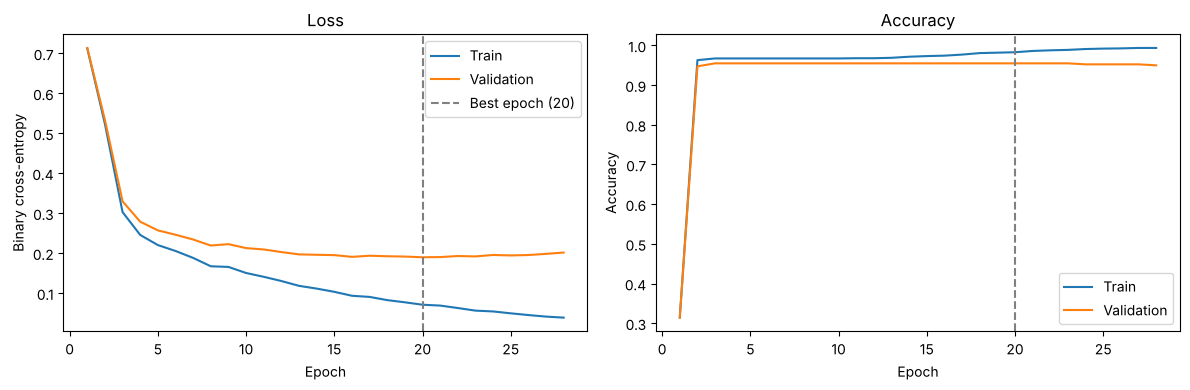

In [7]:
epochs = range(1, len(history['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, history['train_loss'], label='Train'); ax[0].plot(epochs, history['val_loss'], label='Validation')
ax[0].axvline(best_epoch, color='gray', ls='--', label=f'Best epoch ({best_epoch})')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Binary cross-entropy'); ax[0].legend()
ax[1].plot(epochs, history['train_acc'], label='Train'); ax[1].plot(epochs, history['val_acc'], label='Validation')
ax[1].axvline(best_epoch, color='gray', ls='--')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read this:** training loss keeps falling, while validation loss falls and then flattens or rises. The point where validation stops improving is where early stopping picks the weights. A growing gap between the two lines means overfitting.

## 7. Final evaluation on the unseen test set
This is the only time the test set is used. A simple TF-IDF + Logistic Regression model is included as a sanity check: a deep network should be compared to a simple baseline, and it is not automatically better.

In [8]:
model.eval()
with torch.no_grad():
    test_proba = torch.sigmoid(model(Xt_test)).numpy()
test_pred = (test_proba >= 0.5).astype(int)

lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
lr_proba = lr.predict_proba(X_test)[:, 1]
lr_pred = (lr_proba >= 0.5).astype(int)

def row(name, y, p, proba):
    return {'Model': name, 'Accuracy': accuracy_score(y, p), 'Precision': precision_score(y, p),
            'Recall': recall_score(y, p), 'F1': f1_score(y, p), 'ROC-AUC': roc_auc_score(y, proba)}
results = pd.DataFrame([row('Neural network (PyTorch)', y_test, test_pred, test_proba),
                        row('Logistic Regression (baseline)', y_test, lr_pred, lr_proba)]).set_index('Model').round(4)
print('Always predicting "ham" would give accuracy:', round(1 - y_test.mean(), 4))
results

Always predicting "ham" would give accuracy: 0.6867


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Neural network (PyTorch),0.9499,0.92,0.92,0.92,0.9485
Logistic Regression (baseline),0.9499,0.92,0.92,0.92,0.9442


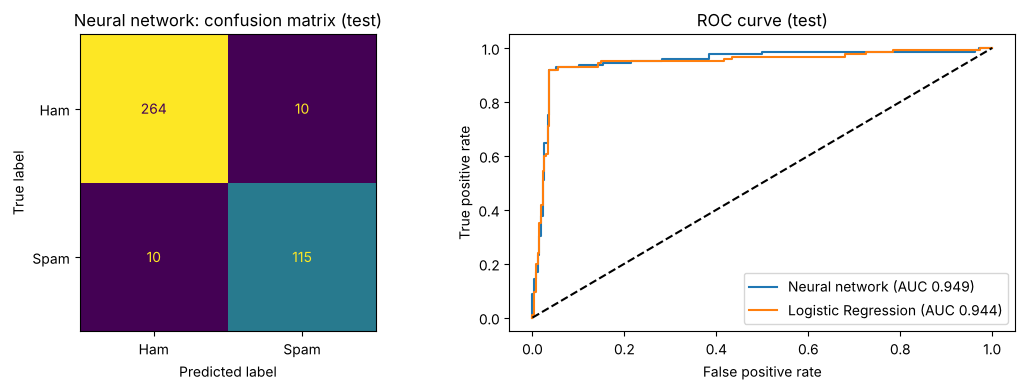

20 wrong out of 399. A few of them (about 3% of labels were randomly flipped on purpose):


,text,label,spam_prob,predicted
1208,your parcel from Anna arrived at the airport,1,0.277,0
1560,the dear text me the address of the college,1,0.072,0
1558,congratulations Anna! mialc cash prize of $100...,0,0.988,1
2525,can you send me the notes from class at 8 the,1,0.060,0
649,now ok please reply when you see this,1,0.121,0
488,congratulations karan! claim a free holiday be...,0,0.969,1


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=['Ham', 'Spam']).plot(ax=ax[0], colorbar=False)
ax[0].set_title('Neural network: confusion matrix (test)')
for name, pr in [('Neural network', test_proba), ('Logistic Regression', lr_proba)]:
    fpr, tpr, _ = roc_curve(y_test, pr); ax[1].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_test, pr):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC curve (test)'); ax[1].set_xlabel('False positive rate')
ax[1].set_ylabel('True positive rate'); ax[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

errors = test_df.assign(spam_prob=test_proba.round(3), predicted=test_pred)
errors = errors[errors.predicted != errors.label]
print(f'{len(errors)} wrong out of {len(test_df)}. A few of them (about 3% of labels were randomly flipped on purpose):')
errors.head(6)

## 8. Predict on new, unseen messages
`predict_messages` takes raw text, applies the **saved** TF-IDF vectorizer, and returns the label with a confidence. Confidence is the probability of the predicted class. Messages near 50% are uncertain and are good candidates for human review.

In [10]:
def predict_messages(messages, threshold=0.5):
    model.eval()
    X = to_t(tfidf.transform(messages))
    with torch.no_grad():
        p_spam = torch.sigmoid(model(X)).numpy()
    out = pd.DataFrame({'message': messages, 'prediction': np.where(p_spam >= threshold, 'SPAM', 'ham'),
                        'confidence': np.where(p_spam >= threshold, p_spam, 1 - p_spam).round(3),
                        'spam_probability': p_spam.round(3)})
    return out

samples = [
    'WINNER! you have won a free holiday. call now to claim',
    'URGENT: your HDFC account is suspended, verify at http://hdfc-secure.com',
    'hey Priya are you coming to the cafe tonight',
    'can you send me the notes from class tomorrow',
    'congratulations! claim a cash prize of $1000 before midnight, reply YES',
    'the free trial of the app ends tomorrow, want to cancel it?',          # looks spammy (free) but is normal
    'please call me when you reach the station',
    'earn money from home, join today',
    'completely different sentence about quantum physics homework',          # words the model has never seen
]
predict_messages(samples)

,message,prediction,confidence,spam_probability
0,WINNER! you have won a free holiday. call now ...,SPAM,0.972,0.972
1,"URGENT: your HDFC account is suspended, verify...",SPAM,0.980,0.980
2,hey Priya are you coming to the cafe tonight,ham,0.859,0.141
3,can you send me the notes from class tomorrow,ham,0.940,0.060
4,congratulations! claim a cash prize of $1000 b...,SPAM,0.991,0.991
5,"the free trial of the app ends tomorrow, want ...",ham,0.950,0.050
6,please call me when you reach the station,ham,0.967,0.033
7,"earn money from home, join today",SPAM,0.937,0.937
8,completely different sentence about quantum ph...,ham,0.646,0.354


**Notes on these results**
- Normal messages that use "free" or "win" in a harmless way are the hardest cases. Check their probabilities.
- The last sample uses words the model never saw, so TF-IDF ignores them. The model then falls back on its general lean towards "ham", so its confidence is not meaningful for text unlike the training data.

## 9. Save the model and vectorizer

In [11]:
import joblib
torch.save({'state_dict': model.state_dict(), 'n_in': Xt_train.shape[1], 'best_epoch': best_epoch}, 'spam_model.pt')
joblib.dump(tfidf, 'tfidf_vectorizer.joblib')

# reload and confirm identical predictions
ck = torch.load('spam_model.pt')
m2 = SpamNet(ck['n_in']); m2.load_state_dict(ck['state_dict']); m2.eval()
with torch.no_grad():
    same = torch.allclose(torch.sigmoid(m2(Xt_test)), torch.sigmoid(model(Xt_test)))
print('Saved spam_model.pt and tfidf_vectorizer.joblib. Reloaded predictions match:', same)

Saved spam_model.pt and tfidf_vectorizer.joblib. Reloaded predictions match: True


## Summary
- TF-IDF (fitted on training data only) feeds a 3-layer PyTorch network with BatchNorm and Dropout; early stopping on validation loss restores the best weights.
- Loss and accuracy curves show convergence and the point where validation stopped improving.
- The test set was touched once, and a Logistic Regression baseline gives context for the network's score.
- The neural network scored about the same as the simple Logistic Regression baseline. On easy text data like this, a deep network is not automatically better, so always compare against a simple model.
- **Limits:** the data is synthetic and built from templates, so scores are higher than a real SMS dataset would give, and they say little about real spam. Real spam changes quickly, so a deployed filter needs regular retraining and a way for people to review uncertain messages. For richer language understanding, replace TF-IDF with pretrained embeddings or a transformer such as DistilBERT.